<a href="https://colab.research.google.com/github/Prajnaa002/Applied_Probability_and_Statistics/blob/main/APS_Sep9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

In [ ]:
#Load the dataset

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns = data.feature_names
)

y = pd.Series(
    (data.target == 0).astype(int),
    name = 'malignant'
)

print(y.value_counts())

print("Feature matrix shape: ", X.shape)
print("Target shape: ", y.shape)
print("Class Names: ", data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape:  (569, 30)
Target shape:  (569,)
Class Names:  ['malignant' 'benign']


In [ ]:
#examine the class distribution

class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": data.target_names,
    "Count": class_counts.values,
    "Probability": class_counts.values / len(y)
})

print(class_distribution)

       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


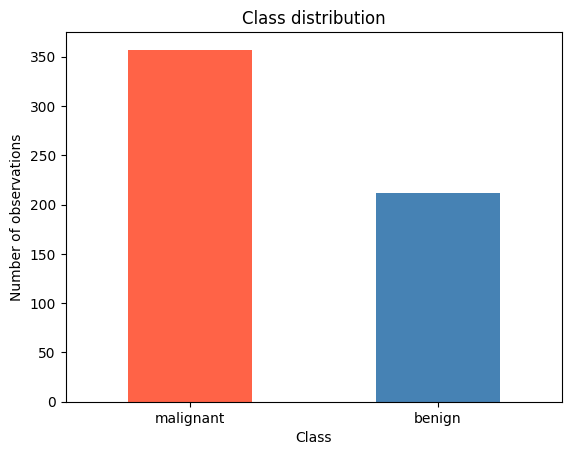

In [ ]:
class_distribution.plot(
    x = "Class",
    y = "Count",
    kind = "bar",
    legend = False,
    color = ["tomato", "steelblue"]
)

plt.ylabel("Number of observations")
plt.title("Class distribution")
plt.xticks(rotation = 0)
plt.show()

are malignant and beningn outcomes equally likely in this dataset

In [ ]:
# 'y' is the column containing your target labels (e.g., Blue or Red)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42, # Ensures the exact same "random" split every time
    stratify=y       # Ensures the Blue/Red ratio stays perfectly balanced
)

print("Training Size:", len(y_train))
print("Testing Size:", len(y_test))

print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).sort_index())


Training Size: 455
Testing Size: 114

Training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [ ]:
#train a logistic regression model

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter = 1000
    )
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
#obtain predicted probabilities
probabilities = model.predict_proba(X_test)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
print(probabilities[:5].sum(axis=1))

[1. 1. 1. 1. 1.]


In [ ]:
results = pd.DataFrame({
    "Actual_class": y_test.values,
    "P_malignant": probabilities[:, 0],
    "P_benign": probabilities[:, 1]
})

print(results.head(10))

   Actual_class   P_malignant  P_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [ ]:
threshold = 0.50

results["Predicted_malignant"] = (
    results["P_malignant"] >= threshold
).astype(int)

results["Actual_label"] = results["Actual_class"].map({
    1: "Benign",
    0: "Malignant"
})

results["Predicted_label"] = results ["Predicted_malignant"].map({
    1: "Malignant",
    0: "Benign"
})

print(
    results[
        [
            "Actual_label",
            "P_malignant",
            "Predicted_label"
        ]
    ].head(10)
)

  Actual_label   P_malignant Predicted_label
0    Malignant  9.996354e-01       Malignant
1       Benign  1.074660e-08          Benign
2    Malignant  9.574321e-01       Malignant
3       Benign  4.238127e-01          Benign
4    Malignant  4.908445e-01          Benign
5    Malignant  9.993840e-01       Malignant
6       Benign  2.384659e-01          Benign
7    Malignant  9.989878e-01       Malignant
8    Malignant  9.994313e-01       Malignant
9    Malignant  9.892324e-01       Malignant


In [ ]:
#compare different thresholds
for threshold in [.30, 0.50, 0.70]:
  predictions = (
      results["P_malignant"] >= threshold
  ).astype(int)

  print(
      f"Threshold = {threshold}:"
      f"Predicted malignant cases = {predictions.sum()}"
  )

Threshold = 0.3:Predicted malignant cases = 76
Threshold = 0.5:Predicted malignant cases = 74
Threshold = 0.7:Predicted malignant cases = 72


In [ ]:
#construct a confusion matrix
actual_malignant = (y_test.values == 0).astype(int)

for threshold in [0.30, 0.50, 0.70]:
    predicted_malignant = (
      probabilities[:,0] >= threshold
    ).astype(int)

    cm = confusion_matrix(actual_malignant, predicted_malignant)
    print(f"\nThreshold = {threshold}")
    print(cm)


Threshold = 0.3
[[38  4]
 [ 0 72]]

Threshold = 0.5
[[39  3]
 [ 1 71]]

Threshold = 0.7
[[41  1]
 [ 1 71]]


In [ ]:
#verify using sklearn
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred = model.predict(X_test)

print("Sklearn accuracy: ", accuracy_score(y_test, y_pred))
print("Sklearn precision: ", precision_score(y_test, y_pred))
print("Sklearn recall/sensitivity: ", recall_score(y_test, y_pred))
print("Sklearn f1: ", f1_score(y_test, y_pred))

Sklearn accuracy:  0.9649122807017544
Sklearn precision:  0.975
Sklearn recall/sensitivity:  0.9285714285714286
Sklearn f1:  0.9512195121951219


In [ ]:
metric_results = []

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:
    y_pred_threshold = (
      probabilities[:,1] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels = [0,1]
    ).ravel()

    accuracy = (tp + tn) / (tp + fp + tn + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0 # among the tumours predicted as malignant, how many were actually malignant
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0 #sensitivity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    f1 = (
        2 * (precision * recall) / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    metric_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall_sensitivity": recall,
        "Specificity": specificity,
        "F1": f1
    })

    threshold_metrics = pd.DataFrame(metric_results)

display(threshold_metrics.round(3))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall_sensitivity,Specificity,F1
0,0.1,67,5,1,41,0.947,0.891,0.976,0.931,0.932
1,0.3,71,1,1,41,0.982,0.976,0.976,0.986,0.976
2,0.5,71,1,3,39,0.965,0.975,0.929,0.986,0.951
3,0.7,72,0,4,38,0.965,1.000,0.905,1.000,0.950
4,0.9,72,0,9,33,0.921,1.000,0.786,1.000,0.880


At which threshold are the fewest malignant tumours missed?

what happens to false positives when the threshold decreases?

which threshold provides the highest specificity?

which threshold provides the best F1 score?

is the threshold with highest accuracy necessarily the safest for tumour detection?

which error is mpore serious in this application?

if missing a malignant tumour is very costly , should the threshold be increased or decreased?



ROC-AUC Score: 0.9573


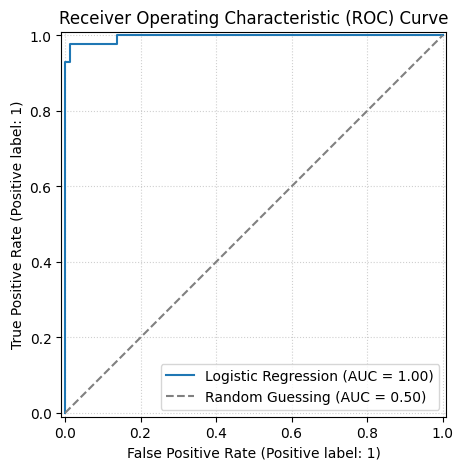

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score, RocCurveDisplay

auc_score = roc_auc_score(y_test, y_pred)
print(f"ROC-AUC Score: {auc_score:.4f}")

# 5. Plot the ROC Curve
# Using from_estimator automatically computes probabilities and handles plotting
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name="Logistic Regression")

# Add a diagonal reference line representing random guessing (chance)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guessing (AUC = 0.50)")
ax.legend(loc="lower right")
ax.set_title("Receiver Operating Characteristic (ROC) Curve")
ax.grid(True, linestyle=":", alpha=0.6)

plt.show()